# One-class autoencoder on the T = 48 benign windows (benign + GridSybil input)

The one-class baseline of `task/autoencoder_benign_t32`, at **T = 48**: the 1D-conv autoencoder of `task/autoencoder`
(14 × 48 in, z = 16, 71,741 parameters) trained on **genuine (benign) windows only** from
`src/data/encoder_input/benign_gridsybil/T48_benign/`. The train / val / test split (80 / 10 / 10 by sender vehicle,
T48_tvt's split) is fixed on disk; train and val hold benign windows only. Val drives early stopping, the LR schedule
and the alarm thresholds. The test splits are opened only in section 5: the benign test split and the GridSybil windows
of the same test vehicles (`test_gridsybil`).

Two label-free scores per window: the reconstruction error (masked MSE over real rows), and the **Mahalanobis
distance** of z to a Gaussian fitted on the benign train z. Each is also aggregated per **track** (one link = one
receiver hearing one sender pseudonym): max and mean over the track's windows.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`python -m task.autoencoder_benign_t48.train` and `python -m task.autoencoder_benign_t48.evaluate`. Sections: 1 input,
2 model, 3 training record, 4 reconstruction on val, 5 test, 6 context, 7 analysis. One seed; a side experiment, not a
thesis result.

Setup: repo-root check, package imports, the run folder (`runs/seed0`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_benign_t48/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_benign_t48.config import ATTACK_TEST_SPLIT, BENIGN_TEST_SPLIT, EVAL_SPLITS, TOTAL_PARAMS, AutoencoderConfig
from task.autoencoder_benign_t48.data import WindowDataset
from task.autoencoder_benign_t48.evaluate import SplitScores
from task.autoencoder_benign_t48.model import ConvAutoencoder, count_params
from task.autoencoder_benign_t48.scoring import Mahalanobis, TrackScores, quantile_thresholds
from task.autoencoder_benign_t48.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score

settings = AutoencoderConfig()
RUN = Path(settings.runs_dir) / "seed0"
assert (RUN / "summary.json").exists(), "no finished run: python -m task.autoencoder_benign_t48.train --seed 0"
assert (RUN / "test_metrics.json").exists(), "no evaluation: python -m task.autoencoder_benign_t48.evaluate --seed 0"
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
T = settings.seq_len
print("run folder:", RUN)
print("data:", settings.data_dir)

run folder: task/autoencoder_benign_t48/runs/seed0
data: src/data/encoder_input/benign_gridsybil/T48_benign


## 1. Input

Four splits on disk. Train / val / test hold the **benign** windows of disjoint sender-vehicle sets (T48_tvt's
80 / 10 / 10 split by sender vehicle, seed 0); `test_gridsybil` holds the GridSybil windows of the **test** vehicles
(GridSybil windows of train / val vehicles were dropped when the input was built). Counts below come from
`metadata.json`; the test splits themselves are not opened before section 5.

In [2]:
order = ["train", "val", "test", "test_gridsybil"]
rows = {}
for name in order:
    (cls, c), = META["counts_by_split_bucket_class"][name][f"b{T}"].items()
    rows[name] = {"class": cls, "windows": c["windows"], "messages": c["messages"], "padding share": c["padding_share"]}
cbs = pd.DataFrame(rows).T
cbs

,class,windows,messages,padding share
train,Benign,112890,2115104,0.6097
val,Benign,13584,252589,0.6126
test,Benign,13405,248250,0.6142
test_gridsybil,GridSybil,27064,477952,0.6321


Load the two splits used for fitting (from the decoded-shard cache when present) and check them.

In [3]:
splits = {name: WindowDataset.load(settings.data_dir, name, settings.workers, cache_dir=settings.cache_dir)
          for name in ("train", "val")}
train, val = splits["train"], splits["val"]
assert not (set(train.vehicles) & set(val.vehicles)), "a sender vehicle in train and val"
for d in (train, val):
    assert (d.info["label"].astype(int) == 0).all() and (d.info["is_attack"].astype(int) == 0).all()
    assert len(d) == cbs.loc[d.split, "windows"]
print("train and val: benign only, no sender vehicle in both, window counts equal metadata")
pd.DataFrame({d.split: {"windows": len(d), "tracks": len(set(d.tracks)), "sender vehicles": len(set(d.vehicles)),
                        "scenario folders": len(set(d.info["scenario"]))} for d in (train, val)}).T

train and val: benign only, no sender vehicle in both, window counts equal metadata


,windows,tracks,sender vehicles,scenario folders
train,112890,101399,3223,2
val,13584,12218,402,2


Shape: each window is up to 48 messages (1 Hz) of one link × 13 normalised features, padded to 48 rows; padding rows
are zero and a prefix mask marks the real rows. The model gets the 13 features plus the mask as a 14th channel:
**14 × 48** per window. Links longer than 48 messages are cut into consecutive non-overlapping crops (the last one may
be short).

window x: (48, 13) + mask: (48,) -> model input: (14, 48)


,min,median,mean,max,share = 48,share 1-3,padding share
split,,,,,,,
train,1,15.0,18.74,48,0.106,0.136,0.610
val,1,15.0,18.59,48,0.105,0.136,0.613


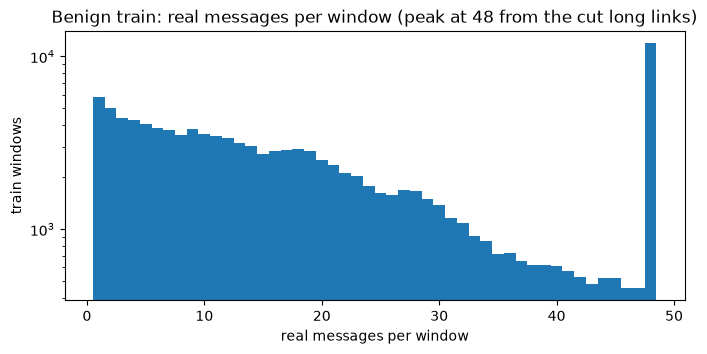

In [4]:
print("window x:", train.x.shape[1:], "+ mask:", train.mask.shape[1:], "-> model input:",
      (settings.n_features + 1, settings.seq_len))
rows = []
for name, d in splits.items():
    n = d.n_messages
    rows.append({"split": name, "min": n.min(), "median": np.median(n), "mean": round(n.mean(), 2), "max": n.max(),
                 f"share = {T}": round(float((n == T).mean()), 3), "share 1-3": round(float((n <= 3).mean()), 3),
                 "padding share": round(1 - d.mask.mean(), 3)})
display(pd.DataFrame(rows).set_index("split"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.n_messages, bins=np.arange(1, T + 2) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("train windows"); ax.set_yscale("log")
ax.set_title(f"Benign train: real messages per window (peak at {T} from the cut long links)")
plt.show()

Per-feature statistics over the **real** train rows (normalised with the benign train mean / std, so ≈ 0 / 1).

In [5]:
real = train.x[train.mask]  # (real rows, 13)
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)},
             index=FEATURES).round(3)

,mean,std,min,max
claimed_pos_x,-0.0,0.999,-1.148,2.383
claimed_pos_y,-0.0,1.000,-1.997,2.382
rx_pos_x,-0.0,0.999,-1.149,2.382
rx_pos_y,0.0,1.000,-1.992,2.377
claimed_vel_x,0.0,1.000,-2.543,2.426
claimed_vel_y,-0.0,1.000,-2.192,2.176
rx_vel_x,-0.0,1.000,-2.546,2.515
rx_vel_y,-0.0,1.000,-2.328,2.216
claimed_acl_x,-0.0,0.999,-5.168,5.166
claimed_acl_y,0.0,0.999,-3.686,3.710


## 2. Model

The `task/autoencoder` ConvAutoencoder (imported). Layers with their output shapes for one batch of 2 windows, and the
trainable parameter count (asserted against the package constant).

In [6]:
model = ConvAutoencoder(settings)
print("model class:", type(model).__module__ + "." + type(model).__name__)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
layer_types = (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear, torch.nn.BatchNorm1d)
hooks = [mod.register_forward_hook(lambda mod, inp, out, name=name: table.append(
    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
    for name, mod in model.named_modules() if isinstance(mod, layer_types)]
model.eval()
with torch.no_grad():
    recon0, z0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
params = count_params(model)
assert params == TOTAL_PARAMS, (params, TOTAL_PARAMS)
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]))
print(f"trainable parameters: {params:,} (= TOTAL_PARAMS)")

model class: task.autoencoder.model.ConvAutoencoder


,layer,type,output (per window),params
0,encoder_conv.0,Conv1d,"(32, 48)",1376
1,encoder_conv.1,BatchNorm1d,"(32, 48)",64
2,encoder_conv.3,Conv1d,"(64, 24)",6208
3,encoder_conv.4,BatchNorm1d,"(64, 24)",128
4,encoder_conv.6,Conv1d,"(64, 12)",12352
5,encoder_conv.7,BatchNorm1d,"(64, 12)",128
6,to_z,Linear,"(16,)",12304
7,from_z,Linear,"(768,)",13056
8,decoder_conv.1,ConvTranspose1d,"(64, 24)",16448
9,decoder_conv.2,BatchNorm1d,"(64, 24)",128


reconstruction: (48, 13)  z: (16,)
trainable parameters: 71,741 (= TOTAL_PARAMS)


## 3. Training record

What `task.autoencoder_benign_t48.train` wrote: the settings (compared with `task/autoencoder_benign_t32`'s defaults),
the summary (thresholds shown in section 5), the per-epoch history (train vs validation masked MSE, best epoch, LR
drops; then the gradient L2 norm, mean and max over the epoch's batches, before clipping, and the LR) and log lines.

In [7]:
from task.autoencoder_benign_t32.config import AutoencoderConfig as SiblingConfig

run_cfg = json.loads((RUN / "config.json").read_text())
sib = SiblingConfig().to_dict()
diff = {k: (sib.get(k), v) for k, v in run_cfg.items() if sib.get(k) != v}
print("settings that differ from task/autoencoder_benign_t32 (sibling, this run):")
for k, (a, b) in diff.items():
    print(f"  {k}: {a!r} -> {b!r}")
assert set(diff) == {"data_dir", "runs_dir", "cache_dir", "seq_len"}, diff
print(json.dumps(json.loads((RUN / "env.json").read_text()), indent=1))

settings that differ from task/autoencoder_benign_t32 (sibling, this run):
  data_dir: 'src/data/encoder_input/all/T32_benign' -> 'src/data/encoder_input/benign_gridsybil/T48_benign'
  runs_dir: 'task/autoencoder_benign_t32/runs' -> 'task/autoencoder_benign_t48/runs'
  cache_dir: 'task/autoencoder_benign_t32/cache' -> 'task/autoencoder_benign_t48/cache'
  seq_len: 32 -> 48
{
 "python": "3.14.5",
 "torch": "2.14.1",
 "numpy": "2.5.3",
 "platform": "macOS-26.4-arm64-arm-64bit-Mach-O",
 "device": "mps",
 "git_commit": "02c9e9b4208c54709e0a7f3070b1f761357f4d29",
 "git_dirty": true,
 "argv": [
  "/Users/bibekgupta/Downloads/projects/sybil-llm/task/autoencoder_benign_t48/train.py",
  "--seed",
  "0"
 ]
}


{
  "run_id": "seed0",
  "params": 71741,
  "best_epoch": 143,
  "best_val_loss": 0.14769670532351584,
  "epochs_run": 153,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 108,
      "from": 0.001,
      "to": 0.0005
    },
    {
      "after_epoch": 115,
      "from": 0.0005,
      "to": 0.00025
    },
    {
      "after_epoch": 122,
      "from": 0.00025,
      "to": 0.000125
    },
    {
      "after_epoch": 130,
      "from": 0.000125,
      "to": 6.25e-05
    },
    {
      "after_epoch": 142,
      "from": 6.25e-05,
      "to": 3.125e-05
    },
    {
      "after_epoch": 149,
      "from": 3.125e-05,
      "to": 1.5625e-05
    }
  ],
  "train_seconds": 1259.4,
  "train_windows": 112890,
  "val_windows": 13584,
  "train_tracks": 101399,
  "val_tracks": 12218,
  "train_vehicles": 3223,
  "val_vehicles": 402,
  "mahalanobis": {
    "cond": 13.992185914676165,
    "shrinkage": 0.0
  },
  "threshold_source": "benign val split",
  "wall_seconds": 1265.4,

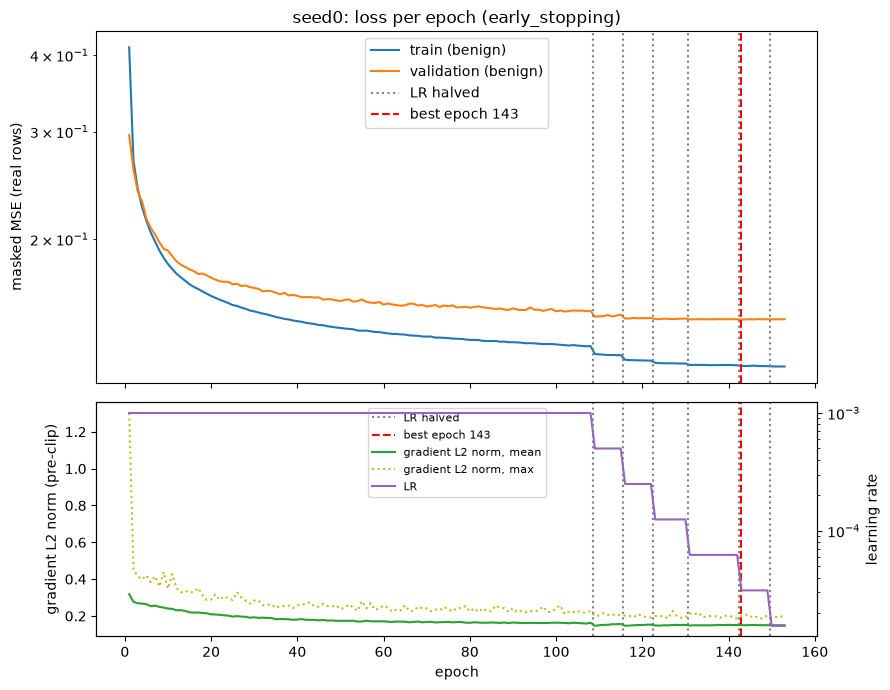

,train_loss,val_loss,lr,grad_norm_mean,grad_norm_max,seconds
epoch,,,,,,
1,0.41202,0.29589,0.00100,0.31860,1.30181,2.93
2,0.26857,0.26004,0.00100,0.27672,0.45044,1.91
143,0.12408,0.14770,0.00003,0.15082,0.19966,3.55
153,0.12375,0.14791,0.00002,0.14977,0.19035,357.17


2026-11-10T18:23:10 train 112,890 / val 13,584 benign windows (5s to load), shape (48, 13) + mask; vehicles 3,223 / 402; tracks 101,399 / 12,218
2026-11-10T18:23:10 padding share train 0.610 / val 0.613, real messages per window median 15, 1-3-row windows train 0.136 / val 0.136
2026-11-10T18:23:10 ConvAutoencoder: 71,741 trainable parameters, input 14 x 48, z 16
2026-11-10T18:23:10 fit: 112,890 benign windows, val: 13,584 benign windows, batch 256, device mps, grad_clip 1, early stopping on val loss (min_delta 0.0001 relative, patience 10)
2026-11-10T18:23:13 epoch   1  train 0.41202  val 0.29589  lr 1.00e-03  grad_norm 0.3186/1.3018  2.9s *best
2026-11-10T18:23:15 epoch   2  train 0.26857  val 0.26004  lr 1.00e-03  grad_norm 0.2767/0.4504  1.9s *best
...
2026-11-10T18:29:43 epoch 136  train 0.12437  val 0.14781  lr 6.25e-05  grad_norm 0.1496/0.2005  3.6s *best
2026-11-10T18:30:10 epoch 143  train 0.12408  val 0.14770  lr 3.13e-05  grad_norm 0.1508/0.1997  3.5s *best
...
2026-11-10T18

In [8]:
summary = json.loads((RUN / "summary.json").read_text())
print(json.dumps({k: v for k, v in summary.items() if k != "thresholds"}, indent=2))
history = pd.read_json(RUN / "history.jsonl", lines=True)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=(3, 2))
ax.plot(history.epoch, history.train_loss, label="train (benign)")
ax.plot(history.epoch, history.val_loss, label="validation (benign)")
for a in (ax, ax2):
    for k, c in enumerate(summary["lr_changes"]):
        a.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", label="LR halved" if k == 0 else None)
    a.axvline(summary["best_epoch"], color="red", ls="--", label=f"best epoch {summary['best_epoch']}")
ax.set_yscale("log"); ax.set_ylabel("masked MSE (real rows)"); ax.legend()
ax.set_title(f"{RUN.name}: loss per epoch ({summary['stop_reason']})")
ax2.plot(history.epoch, history.grad_norm_mean, color="tab:green", label="gradient L2 norm, mean")
ax2.plot(history.epoch, history.grad_norm_max, color="tab:olive", ls=":", label="gradient L2 norm, max")
ax2.set_ylabel("gradient L2 norm (pre-clip)"); ax2.set_xlabel("epoch")
lr_ax = ax2.twinx(); lr_ax.plot(history.epoch, history.lr, color="tab:purple", label="LR"); lr_ax.set_yscale("log")
lr_ax.set_ylabel("learning rate")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = lr_ax.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout(); plt.show()
display(history.iloc[sorted({0, 1, summary["best_epoch"] - 1, len(history) - 1})].set_index("epoch").round(5))
log = (RUN / "train.log").read_text().splitlines()
print("\n".join(log[:6] + ["..."] + [l for l in log if "*best" in l][-2:] + ["..."] + log[-4:-1]))

## 4. Reconstruction on val

Load `best.pt` and rebuild the benign val windows: three full val windows, input vs reconstruction for three features;
then the mean reconstruction error per feature over val.

val windows 13,584; mean window error 0.1410; pooled over real rows 0.1477 (run's best val loss 0.1477)


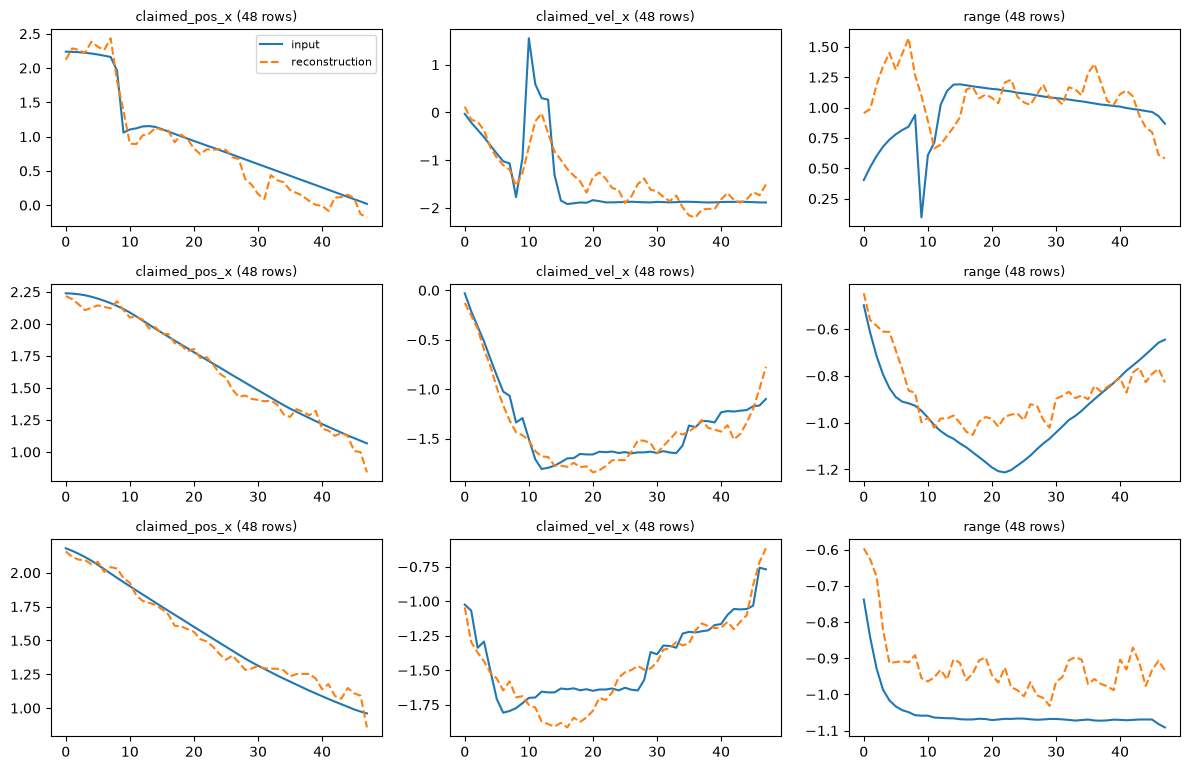

,val MSE
claimed_acl_x,0.5252
claimed_acl_y,0.4248
log_dtau,0.1816
rx_vel_x,0.1388
bearing,0.1379
rx_vel_y,0.1212
claimed_vel_x,0.1000
claimed_vel_y,0.0840
range,0.0521
rx_pos_x,0.0201


In [9]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
val_out = trainer.score(val.x, val.mask, keep_recon=True)
pooled = float((val_out["error"] * val.n_messages).sum() / val.n_messages.sum())
print(f"val windows {len(val):,}; mean window error {val_out['error'].mean():.4f}; "
      f"pooled over real rows {pooled:.4f} (run's best val loss {summary['best_val_loss']:.4f})")

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages == T)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.6 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    n = val.n_messages[i]
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :n, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :n, j], "--", label="reconstruction")
        axes[r, c].set_title(f"{f} ({n} rows)", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="val MSE").sort_values(ascending=False).round(4).to_frame()

## 5. Test

**Scoring first, labels after.** The Mahalanobis model stored by the run (`mahalanobis.npz`, fitted on the benign
train z) is checked against a refit here. Thresholds = 95th / 99th percentile of the **benign val** scores (window
level) or of the val track scores (track level); they are recomputed and compared with the run's summary. Then every
window of the benign test split and of `test_gridsybil` is scored again here (reconstruction error, Mahalanobis
distance, per-track max / mean) and compared with the per-window score files that `evaluate.py` wrote to
`runs/seed0/scores/`, before any label enters a metric.

In [10]:
maha = Mahalanobis.from_state(np.load(RUN / "mahalanobis.npz"))
train_z = trainer.score(train.x, train.mask)["z"]
refit = Mahalanobis(cfg.mahalanobis_max_cond, cfg.mahalanobis_shrinkage).fit(train_z)
print(f"mahalanobis: cond {maha.cond:.3g}, shrinkage {maha.shrinkage:g}; refit on train z matches: "
      f"{np.allclose(maha.mean, refit.mean, atol=1e-5) and np.allclose(maha.precision, refit.precision, rtol=1e-3, atol=1e-4)}")

LEVELS = ["window", "track max", "track mean"]
SCORES = ["reconstruction", "mahalanobis"]


def score_split(d, out=None):
    # Window scores and per-track max / mean of one split; no labels involved.
    out = out if out is not None else trainer.score(d.x, d.mask)
    tr = TrackScores(d.tracks)
    res = {"tracks": tr, "error_feature": out["error_feature"], "z": out["z"], "n_messages": d.n_messages}
    for name, s in (("reconstruction", out["error"]), ("mahalanobis", maha.score(out["z"]))):
        res[(name, "window")] = s
        agg = tr.aggregate(s)
        res[(name, "track max")], res[(name, "track mean")] = agg["max"], agg["mean"]
    return res


scored = {"val": score_split(val, val_out)}
thresholds = {key: quantile_thresholds(scored["val"][key], cfg.threshold_quantiles)
              for key in [(n, l) for n in SCORES for l in LEVELS]}
run_thr = summary["thresholds"]
same = all(np.isclose(thresholds[(n, "window")][q], run_thr["window"][n][q], rtol=1e-4) and
           np.isclose(thresholds[(n, "track max")][q], run_thr["track"][f"{n}_max"][q], rtol=1e-4) and
           np.isclose(thresholds[(n, "track mean")][q], run_thr["track"][f"{n}_mean"][q], rtol=1e-4)
           for n in SCORES for q in ("p95", "p99"))
print("val thresholds equal the run's summary:", same)
assert same
# The metrics below use the run's stored thresholds (summary.json), as evaluate.py does.
thresholds = {(n, l): run_thr["window"][n] if l == "window" else run_thr["track"][f"{n}_{l.split()[1]}"]
              for n in SCORES for l in LEVELS}
display(pd.DataFrame({f"{n} / {l}": thresholds[(n, l)] for n in SCORES for l in LEVELS}).T.round(4))

mahalanobis: cond 14, shrinkage 0; refit on train z matches: True
val thresholds equal the run's summary: True


,p95,p99
reconstruction / window,0.4570,0.7706
reconstruction / track max,0.4710,0.7861
reconstruction / track mean,0.4383,0.7461
mahalanobis / window,6.1997,8.1828
mahalanobis / track max,6.3002,8.2422
mahalanobis / track mean,6.0128,7.9882


In [11]:
test_data = {}
data_by_split = {"val": val}
for name in EVAL_SPLITS:
    d = WindowDataset.load(settings.data_dir, name, settings.workers, cache_dir=settings.cache_dir)
    scored[name] = score_split(d)
    test_data[name] = data_by_split[name] = d
    print(f"scored {name}: {len(d):,} windows, {len(scored[name]['tracks']):,} tracks")

for name, d in data_by_split.items():
    stored = SplitScores.load(RUN / "scores", name)
    assert np.array_equal(stored.ids, d.ids) and np.array_equal(stored.n_messages, d.n_messages), name
    gaps = {s: float(np.max(np.abs(stored.scores[s] - scored[name][(s, "window")]) /
                            np.maximum(np.abs(stored.scores[s]), 1e-12))) for s in SCORES}
    assert all(g < 1e-3 for g in gaps.values()), (name, gaps)
    print(f"{name}: score files aligned with the window ids; max relative gap to this re-scoring "
          + ", ".join(f"{s} {g:.1e}" for s, g in gaps.items()))

scored test: 13,405 windows, 12,053 tracks


scored test_gridsybil: 27,064 windows, 23,904 tracks
val: score files aligned with the window ids; max relative gap to this re-scoring reconstruction 0.0e+00, mahalanobis 0.0e+00
test: score files aligned with the window ids; max relative gap to this re-scoring reconstruction 0.0e+00, mahalanobis 0.0e+00
test_gridsybil: score files aligned with the window ids; max relative gap to this re-scoring reconstruction 0.0e+00, mahalanobis 0.0e+00


Labels are read now. Sanity checks: the benign test split holds label 0 only and `test_gridsybil` only code 16; test
vehicles are disjoint from train / val; no track appears in both test splits (so every track has one label).
Positive = GridSybil.

In [12]:
assert (test_data[BENIGN_TEST_SPLIT].info["label"].astype(int) == 0).all()
assert (test_data[ATTACK_TEST_SPLIT].info["label"].astype(int) == 16).all()
for name in EVAL_SPLITS:
    assert len(test_data[name]) == cbs.loc[name, "windows"]
test_veh = set().union(*(set(d.vehicles) for d in test_data.values()))
assert not (test_veh & set(train.vehicles)) and not (test_veh & set(val.vehicles))
shared = len(set(scored[BENIGN_TEST_SPLIT]["tracks"].tracks) & set(scored[ATTACK_TEST_SPLIT]["tracks"].tracks))
print("labels as expected; test vehicles disjoint from train / val; tracks in both test splits:", shared)
bv, av = set(test_data[BENIGN_TEST_SPLIT].vehicles), set(test_data[ATTACK_TEST_SPLIT].vehicles)
print(f"test sender vehicles: benign {len(bv):,}, GridSybil {len(av):,}, in both {len(bv & av):,}")
rows = {}
for name, d in test_data.items():
    n = d.n_messages
    rows[name] = {"windows": len(d), "tracks": len(scored[name]["tracks"]), "median rows": float(np.median(n)),
                  "share 1-3 rows": round(float((n <= 3).mean()), 3), f"share = {T} rows": round(float((n == T).mean()), 3)}
pd.DataFrame(rows).T

labels as expected; test vehicles disjoint from train / val; tracks in both test splits: 0
test sender vehicles: benign 401, GridSybil 173, in both 0


,windows,tracks,median rows,share 1-3 rows,share = 48 rows
test,13405.0,12053.0,15.0,0.138,0.104
test_gridsybil,27064.0,23904.0,13.0,0.185,0.120


GridSybil vs benign test: AUROC, PR-AUC (chance = GridSybil share), and at the val-p95 / val-p99 thresholds the
GridSybil recall and the benign-test FPR, per window and per track, for both scores. Per window, the AUROC is also given
on the windows with **1-3 real rows** and with **at least 4 real rows** (both classes restricted). A **length-only**
reference uses the fixed rule score = − real messages per window (shorter = more anomalous; fixed in advance, not
chosen on test labels; `task/autoencoder_benign_t32` uses the same rule). Everything is recomputed here with sklearn
from this notebook's own scoring and then compared with `runs/seed0/test_metrics.json`.

In [13]:
B, A = BENIGN_TEST_SPLIT, ATTACK_TEST_SPLIT


def pair(key):
    b, a = scored[B][key], scored[A][key]
    return np.r_[np.zeros(len(b), int), np.ones(len(a), int)], np.r_[b, a]


n_all = np.r_[scored[B]["n_messages"], scored[A]["n_messages"]]
rows = []
for name in SCORES:
    for level in LEVELS:
        y, s = pair((name, level))
        r = {"score": name, "level": level, "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
             "chance": y.mean(), "n benign": int((y == 0).sum()), "n GridSybil": int(y.sum())}
        if level == "window":
            r["AUROC (1-3 rows)"] = roc_auc_score(y[n_all <= 3], s[n_all <= 3])
            r["AUROC (>= 4 rows)"] = roc_auc_score(y[n_all >= 4], s[n_all >= 4])
        for q in ("p95", "p99"):
            th = thresholds[(name, level)][q]
            r[f"recall {q}"] = float((s[y == 1] > th).mean())
            r[f"benign FPR {q}"] = float((s[y == 0] > th).mean())
        rows.append(r)
y_w = np.r_[np.zeros(len(scored[B]["n_messages"]), int), np.ones(len(scored[A]["n_messages"]), int)]
rows.append({"score": "length only (reference)", "level": "window", "AUROC": roc_auc_score(y_w, -n_all.astype(float)),
             "PR-AUC": average_precision_score(y_w, -n_all.astype(float)), "chance": y_w.mean(),
             "n benign": int((y_w == 0).sum()), "n GridSybil": int(y_w.sum())})
res = pd.DataFrame(rows)
print(f"windows with 1-3 rows: benign {int(((n_all <= 3) & (y_w == 0)).sum()):,}, GridSybil {int(((n_all <= 3) & (y_w == 1)).sum()):,}; "
      f">= 4 rows: benign {int(((n_all >= 4) & (y_w == 0)).sum()):,}, GridSybil {int(((n_all >= 4) & (y_w == 1)).sum()):,}")
res.set_index(["score", "level"]).round(3)

windows with 1-3 rows: benign 1,846, GridSybil 5,003; >= 4 rows: benign 11,559, GridSybil 22,061


AUROC  PR-AUC  chance  n benign  \
score                   level                                         
reconstruction          window      0.689   0.829   0.669     13405   
                        track max   0.678   0.815   0.665     12053   
                        track mean  0.681   0.818   0.665     12053   
mahalanobis             window      0.437   0.655   0.669     13405   
                        track max   0.430   0.643   0.665     12053   
                        track mean  0.427   0.641   0.665     12053   
length only (reference) window      0.530   0.697   0.669     13405   

                                    n GridSybil  AUROC (1-3 rows)  \
score                   level                                       
reconstruction          window            27064             0.599   
                        track max         23904               NaN   
                        track mean        23904               NaN   
mahalanobis             window            27064             0.406   
                        track max         23904               NaN   
                        track mean        23904               NaN   
length only (reference) window            27064               NaN   

                                    AUROC (>= 4 rows)  recall p95  \
score                   level                                       
reconstruction          window                  0.720       0.243   
                        track max                 NaN       0.213   
                        track mean                NaN       0.224   
mahalanobis             window                  0.453       0.062   
                        track max                 NaN       0.058   
                        track mean                NaN       0.057   
length only (reference) window                    NaN         NaN   

                                    benign FPR p95  recall p99  benign FPR p99  
score                   level                                                   
reconstruction          window               0.047       0.154           0.008  
                        track max            0.048       0.122           0.008  
                        track mean           0.049       0.124           0.009  
mahalanobis             window               0.044       0.017           0.009  
                        track max            0.044       0.016           0.009  
                        track mean           0.044       0.013           0.008  
length only (reference) window                 NaN         NaN             NaN

The stored `test_metrics.json` (written by `evaluate.py` from the score files) against the table above.

In [14]:
stored = json.loads((RUN / "test_metrics.json").read_text())
worst = 0.0
for _, r in res.iterrows():
    if r.score.startswith("length"):
        m = stored["length_only"]
    elif r.level == "window":
        m = stored["window"][r.score]
    else:
        m = stored["track"][f"{r.score}_{r.level.split()[1]}"]
    pairs = [(r["AUROC"], m["auroc"]), (r["PR-AUC"], m["pr_auc"])]
    if not r.score.startswith("length"):
        pairs += [(r[f"{k} {q}"], m[f"{k.replace(' ', '_').lower()}_{q}"]) for k in ("recall", "benign FPR") for q in ("p95", "p99")]
        if r.level == "window":
            pairs += [(r["AUROC (1-3 rows)"], m["rows_1_3"]["auroc"]), (r["AUROC (>= 4 rows)"], m["rows_ge_4"]["auroc"])]
    worst = max(worst, max(abs(a - b) for a, b in pairs))
print(f"largest |notebook - test_metrics.json| over every metric: {worst:.2e}")
assert worst < 2e-3
print("val alarm rate at the val thresholds (by construction about 0.05 / 0.01):", stored["val_alarm_rate"])

largest |notebook - test_metrics.json| over every metric: 0.00e+00
val alarm rate at the val thresholds (by construction about 0.05 / 0.01): {'reconstruction': {'p95': 0.05005889281507656, 'p99': 0.010011778563015312}, 'mahalanobis': {'p95': 0.05005889281507656, 'p99': 0.010011778563015312}}


Score histograms per window, benign test vs GridSybil, with the val-p95 threshold.

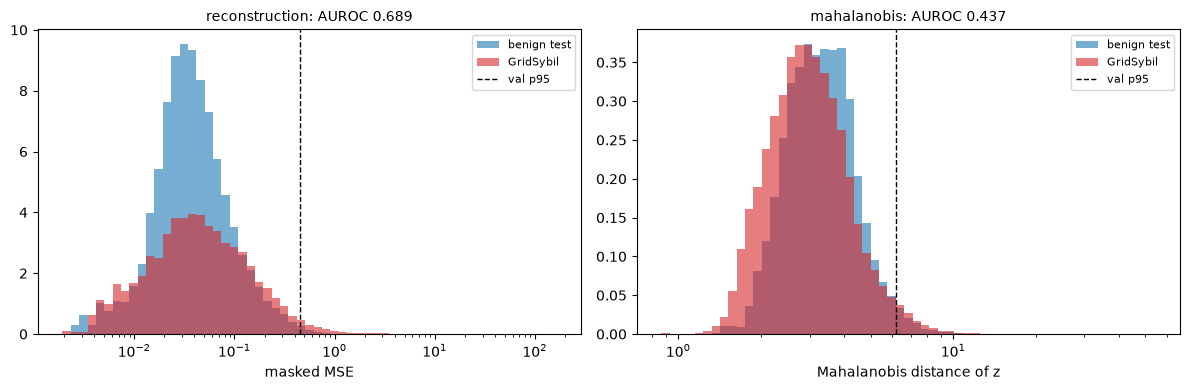

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, SCORES):
    allv = np.concatenate([scored[n][(name, "window")] for n in EVAL_SPLITS])
    bins = np.logspace(np.log10(max(allv.min(), 1e-5)), np.log10(allv.max()), 60)
    ax.hist(scored[B][(name, "window")], bins=bins, alpha=0.6, density=True, label="benign test")
    ax.hist(scored[A][(name, "window")], bins=bins, alpha=0.6, density=True, label="GridSybil", color="tab:red")
    ax.axvline(thresholds[(name, "window")]["p95"], color="black", ls="--", lw=1, label="val p95")
    y, s = pair((name, "window"))
    ax.set_xscale("log"); ax.set_title(f"{name}: AUROC {roc_auc_score(y, s):.3f}", fontsize=10)
    ax.set_xlabel("masked MSE" if name == "reconstruction" else "Mahalanobis distance of z")
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

Reconstruction error vs real messages per window (median per length), and the window-length distribution of the two test splits.

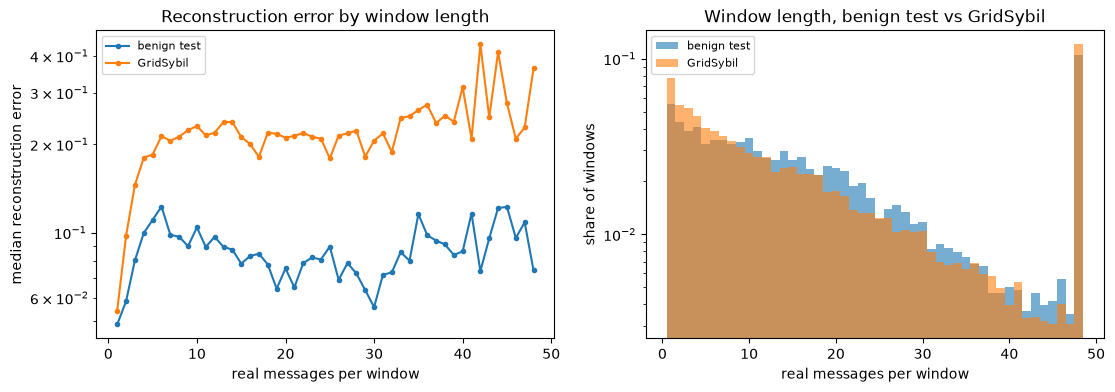

In [16]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for n, lab in [(B, "benign test"), (A, "GridSybil")]:
    df = pd.DataFrame({"n": scored[n]["n_messages"], "e": scored[n][("reconstruction", "window")]})
    g = df.groupby("n").e.median()
    ax.plot(g.index, g.values, marker=".", label=lab)
    ax2.hist(scored[n]["n_messages"], bins=np.arange(1, T + 2) - 0.5, alpha=0.6, density=True, label=lab)
ax.set_yscale("log"); ax.set_xlabel("real messages per window"); ax.set_ylabel("median reconstruction error")
ax.legend(fontsize=8); ax.set_title("Reconstruction error by window length")
ax2.set_xlabel("real messages per window"); ax2.set_ylabel("share of windows"); ax2.set_yscale("log")
ax2.legend(fontsize=8); ax2.set_title("Window length, benign test vs GridSybil")
plt.show()

Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC of GridSybil vs benign test.

In [17]:
ef = {n: scored[n]["error_feature"] for n in EVAL_SPLITS}
e = np.r_[ef[B], ef[A]]
tab = pd.DataFrame({"mean error benign": ef[B].mean(0), "mean error GridSybil": ef[A].mean(0),
                    "AUROC": [roc_auc_score(y_w, e[:, j]) for j in range(e.shape[1])]}, index=FEATURES)
tab.round(3)

,mean error benign,mean error GridSybil,AUROC
claimed_pos_x,0.016,0.169,0.632
claimed_pos_y,0.013,0.248,0.719
rx_pos_x,0.019,0.098,0.570
rx_pos_y,0.014,0.107,0.642
claimed_vel_x,0.100,0.184,0.559
claimed_vel_y,0.080,0.175,0.611
rx_vel_x,0.138,0.215,0.546
rx_vel_y,0.118,0.256,0.600
claimed_acl_x,0.505,1.020,0.575
claimed_acl_y,0.436,1.124,0.625


2-D PCA of the latent z (fitted on the benign test z; 4,000 windows per class; inspection only).

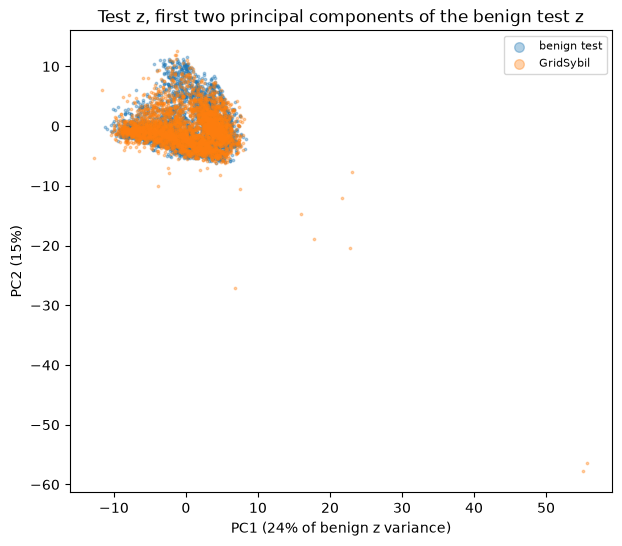

In [18]:
rng = np.random.default_rng(0)
pca = PCA(2, random_state=0).fit(scored[B]["z"])
fig, ax = plt.subplots(figsize=(7, 6))
for n, lab in [(B, "benign test"), (A, "GridSybil")]:
    z = scored[n]["z"]
    zz = pca.transform(z[rng.choice(len(z), size=min(4000, len(z)), replace=False)])
    ax.scatter(zz[:, 0], zz[:, 1], s=3, alpha=0.35, label=lab)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of benign z variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=4, fontsize=8); ax.set_title("Test z, first two principal components of the benign test z")
plt.show()

## 6. Context (not a fair comparison)

Other autoencoders in `task/`, GridSybil vs benign window AUROC on their own test splits (numbers from `agent.md`):

- one-class ConvAutoencoder at T = 32 on the benign windows of all 8 folders (`task/autoencoder_benign_t32`):
  reconstruction **0.736**, Mahalanobis 0.510, length alone 0.559;
- unsupervised ConvAutoencoders trained on benign + GridSybil as "normal", T = 48 (`task/autoencoder`,
  `task/autoencoder_overlap`): reconstruction **0.484**;
- supervised autoencoder with a classifier head, T = 48 (`task/autoencoder_st`, GridSybil labels in training): **0.929**.

Different inputs, normalisation, window length, splits or training signal: these numbers frame the result, they do not
rank the models.

In [19]:
ctx = res[res.level == "window"].set_index("score")[["AUROC"]].rename(columns={"AUROC": "GridSybil window AUROC"})
ctx.index = [f"this run (T48 one-class): {i}" for i in ctx.index]
ctx.loc["task/autoencoder_benign_t32, T32 one-class, reconstruction (context)"] = 0.736
ctx.loc["task/autoencoder(_overlap), T48, unsupervised (context)"] = 0.484
ctx.loc["task/autoencoder_st, T48, supervised (context)"] = 0.929
ctx.round(3)

,GridSybil window AUROC
this run (T48 one-class): reconstruction,0.689
this run (T48 one-class): mahalanobis,0.437
this run (T48 one-class): length only (reference),0.530
"task/autoencoder_benign_t32, T32 one-class, reconstruction (context)",0.736
"task/autoencoder(_overlap), T48, unsupervised (context)",0.484
"task/autoencoder_st, T48, supervised (context)",0.929


The numbers the analysis below refers to.

In [20]:
results = {"run": RUN.name, "params": summary["params"], "best_epoch": summary["best_epoch"],
           "best_val_loss": round(summary["best_val_loss"], 5), "epochs_run": summary["epochs_run"],
           "stop_reason": summary["stop_reason"], "lr_changes": len(summary["lr_changes"]),
           "train_minutes": round(summary["train_seconds"] / 60, 1),
           "val_loss_epoch_1": round(float(history.val_loss.iloc[0]), 4),
           "train_loss_at_best": round(float(history.train_loss.iloc[summary["best_epoch"] - 1]), 4)}
for _, r in res.iterrows():
    keys = [k for k in ("AUROC", "AUROC (1-3 rows)", "AUROC (>= 4 rows)", "PR-AUC", "chance", "recall p95",
                        "benign FPR p95", "recall p99", "benign FPR p99") if k in r and pd.notna(r[k])]
    results[f"{r.score}/{r.level}"] = {k: round(float(r[k]), 3) for k in keys}
results

{'run': 'seed0',
 'params': 71741,
 'best_epoch': 143,
 'best_val_loss': 0.1477,
 'epochs_run': 153,
 'stop_reason': 'early_stopping',
 'lr_changes': 6,
 'train_minutes': 21.0,
 'val_loss_epoch_1': 0.2959,
 'train_loss_at_best': 0.1241,
 'reconstruction/window': {'AUROC': 0.689,
  'AUROC (1-3 rows)': 0.599,
  'AUROC (>= 4 rows)': 0.72,
  'PR-AUC': 0.829,
  'chance': 0.669,
  'recall p95': 0.243,
  'benign FPR p95': 0.047,
  'recall p99': 0.154,
  'benign FPR p99': 0.008},
 'reconstruction/track max': {'AUROC': 0.678,
  'PR-AUC': 0.815,
  'chance': 0.665,
  'recall p95': 0.213,
  'benign FPR p95': 0.048,
  'recall p99': 0.122,
  'benign FPR p99': 0.008},
 'reconstruction/track mean': {'AUROC': 0.681,
  'PR-AUC': 0.818,
  'chance': 0.665,
  'recall p95': 0.224,
  'benign FPR p95': 0.049,
  'recall p99': 0.124,
  'benign FPR p99': 0.009},
 'mahalanobis/window': {'AUROC': 0.437,
  'AUROC (1-3 rows)': 0.406,
  'AUROC (>= 4 rows)': 0.453,
  'PR-AUC': 0.655,
  'chance': 0.669,
  'recall p95':

## 7. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals). A side experiment that fills the
T = 48 one-class cell of the autoencoder baseline grid; not a thesis detection result, the TimesNet plan is unchanged
(RULE 1: reported as produced).

- **Training worked as a reconstruction model of benign traffic.** 71,741 parameters. Benign val masked MSE fell from
  0.296 (epoch 1) to **0.1477** (best, epoch 143); early stopping (min_delta 1e-4 relative, patience 10) ended the run
  at epoch 153 after 6 LR halvings (1e-3 to 1.6e-5, the first after epoch 108). Train loss at the best epoch is 0.124,
  so val / train = 1.19: a wider gap than the T = 32 sibling (0.1005 vs 0.1050), with 4.5 times fewer train windows
  here (112,890 vs 502,773). Acceleration is the hardest feature to rebuild (val MSE 0.53 / 0.42), positions the
  easiest (0.014-0.020).
- **Calibration transfers from val to test.** Thresholds are benign-val quantiles; on the benign test windows the
  false-positive rate is 0.047 at val p95 and 0.008 at val p99 (window level; track level 0.048-0.049 / 0.008-0.009).
- **GridSybil: the reconstruction error detects part of it.** Window AUROC **0.689** (PR-AUC 0.829 against a chance
  level of 0.669, the GridSybil share of the test windows); at val p95 recall **0.243** (p99: 0.154). On the windows
  with at least 4 real rows the AUROC is 0.720, on the 1-3-row windows 0.599. Per track it does not improve (max
  0.678, mean 0.681; recall at val p95 0.213 / 0.224). GridSybil windows are rebuilt worst on log-Δτ (mean error 3.21
  vs 0.18 benign) and range (0.95 vs 0.05); the per-feature AUROC is highest for range (0.753) and claimed_pos_y
  (0.719).
- **Window length explains little of it.** Length alone, with the fixed rule score = −n_messages (shorter = more
  anomalous; the rule of `task/autoencoder_benign_t32`, so no difference in convention), gives AUROC 0.530 (PR-AUC
  0.697): 18.5% of GridSybil and 13.8% of benign test windows hold 1-3 messages.
- **Mahalanobis on z is below chance:** window AUROC **0.437** (0.406 on 1-3 rows, 0.453 on at least 4 rows), track
  0.430 / 0.427; recall at val p95 0.062 with a benign FPR of 0.044. GridSybil windows sit closer to the centre of the
  benign z distribution than benign test windows do. Flipping the sign would be a direction chosen on test labels, so
  it is not a result.
- **Against the T = 32 one-class sibling (context only):** 0.689 here vs 0.736 there for the reconstruction error on
  GridSybil (0.720 vs 0.778 on windows with at least 4 rows; Mahalanobis 0.437 vs 0.510). The two runs differ in more
  than T: the sibling trains on the benign windows of all 8 folders (the same traffic about 4 times, F1) with its own
  split, benign test set and normalisation, so the difference cannot be attributed to the window length.
- **Caveats.** One seed. GridSybil only: the run says nothing about DataReplay or DoS. The benign and GridSybil test
  windows come from different sender vehicles (401 benign, 173 GridSybil, none in both), all disjoint from train / val.
  Track ids hold the true sender (F13: the ghosts share pseudonym 1). Normalisation is fitted on benign train rows
  only, so GridSybil values are measured on the benign scale by design.